# Customer Segmentation Analysis

**Internship:** Oasis Infobyte Data Analytics Internship

**Project:** Task 2 – Customer Segmentation Analysis

**Dataset:** UCI Online Retail Dataset

## Project Objective

The objective of this project is to segment customers based on their purchasing behaviour using Recency, Frequency, and Monetary (RFM) analysis and the K-Means clustering algorithm.

## Project Overview

In this project, customer transaction data is cleaned and analyzed to understand purchasing patterns. RFM analysis is used to calculate customer recency, frequency, and monetary value. The K-Means clustering algorithm is then applied to group customers into different segments.

## Tools and Technologies

* Python
* Jupyter Notebook
* Pandas and NumPy
* Matplotlib
* Scikit-learn

## Expected Outcome

The analysis aims to identify different customer groups, understand their purchasing behaviour, and suggest suitable marketing strategies for each segment.


In [1]:
import os

os.chdir(r"B:\Oasis_Week1\DataAnalytics-L1-CustomerSegmentation")

print(os.getcwd())
print(os.listdir())

B:\Oasis_Week1\DataAnalytics-L1-CustomerSegmentation
['.ipynb_checkpoints', 'Customer_Segmentation.ipynb', 'Online Retail.xlsx']


In [2]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
import os
import numpy as np
import pandas as pd

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Current folder:", os.getcwd())

NumPy version: 1.26.4
Pandas version: 2.2.3
Current folder: B:\Oasis_Week1\DataAnalytics-L1-CustomerSegmentation


In [5]:
# Load the Online Retail dataset
df = pd.read_excel("Online Retail.xlsx")

# Display the first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Check the number of rows and columns

print("Dataset Shape:", df.shape)

# Check column names and data types

print("\nDataset Information:")
df.info()

# Check missing values in each column

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [7]:
# Remove rows where CustomerID is missing
df = df.dropna(subset=["CustomerID"])

# Remove rows with missing product descriptions
df = df.dropna(subset=["Description"])

# Remove cancelled transactions
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Reset the index
df = df.reset_index(drop=True)

# Check the cleaned dataset
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Cleaned Dataset Shape: (397884, 8)

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [8]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [9]:
import pandas as pd

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [10]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4])
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4])

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,4
12347.0,2,7,4310.00,4,4,4
12348.0,75,4,1797.24,2,3,4
12349.0,19,1,1757.55,3,1,4
12350.0,310,1,334.40,1,1,2


In [11]:
rfm["RFM_Score"] = rfm["R_Score"].astype(int) + rfm["F_Score"].astype(int) + rfm["M_Score"].astype(int)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,6
12347.0,2,7,4310.00,4,4,4,12
12348.0,75,4,1797.24,2,3,4,9
12349.0,19,1,1757.55,3,1,4,8
12350.0,310,1,334.40,1,1,2,4


In [12]:
import pandas as pd

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4])
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4])

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,4
12347.0,2,7,4310.00,4,4,4
12348.0,75,4,1797.24,2,3,4
12349.0,19,1,1757.55,3,1,4
12350.0,310,1,334.40,1,1,2


In [13]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

df = df.dropna(subset=["CustomerID", "Description"])

df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df = df.reset_index(drop=True)

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("Dataset Shape:", df.shape)

Dataset Shape: (397884, 9)


In [14]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4])
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4])

rfm["RFM_Score"] = rfm["R_Score"].astype(int) + rfm["F_Score"].astype(int) + rfm["M_Score"].astype(int)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,6
12347.0,2,7,4310.00,4,4,4,12
12348.0,75,4,1797.24,2,3,4,9
12349.0,19,1,1757.55,3,1,4,8
12350.0,310,1,334.40,1,1,2,4


In [15]:
from sklearn.preprocessing import StandardScaler

features = rfm[["Recency", "Frequency", "Monetary"]]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(features)

print("Scaled Data Shape:", rfm_scaled.shape)

Scaled Data Shape: (4338, 3)


In [16]:
import sklearn
print(sklearn.__version__)

1.9.1


In [17]:
from sklearn.preprocessing import StandardScaler

features = rfm[["Recency", "Frequency", "Monetary"]]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(features)

print("Scaled Data Shape:", rfm_scaled.shape)

Scaled Data Shape: (4338, 3)


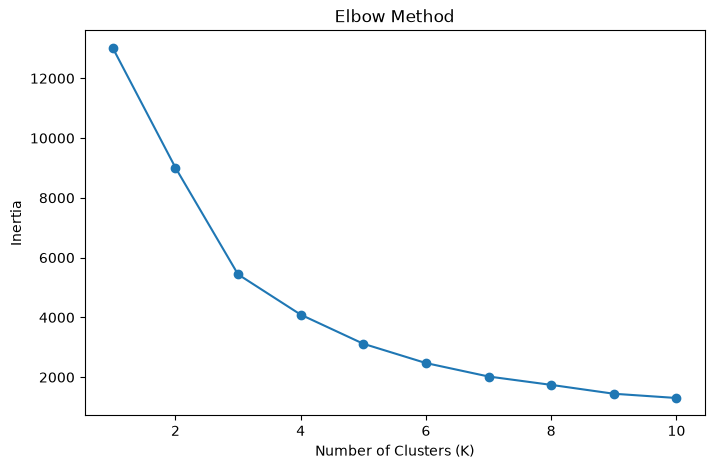

In [18]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [19]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print(rfm[["Recency", "Frequency", "Monetary", "Cluster"]].head())

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         326          1  77183.60        0
12347.0           2          7   4310.00        1
12348.0          75          4   1797.24        1
12349.0          19          1   1757.55        1
12350.0         310          1    334.40        0


In [20]:
cluster_summary = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)

print(cluster_summary)

         Recency  Frequency  Monetary
Cluster                              
0         247.11       1.58    631.42
1          41.45       4.67   1855.94
2           6.04      66.42  85904.35


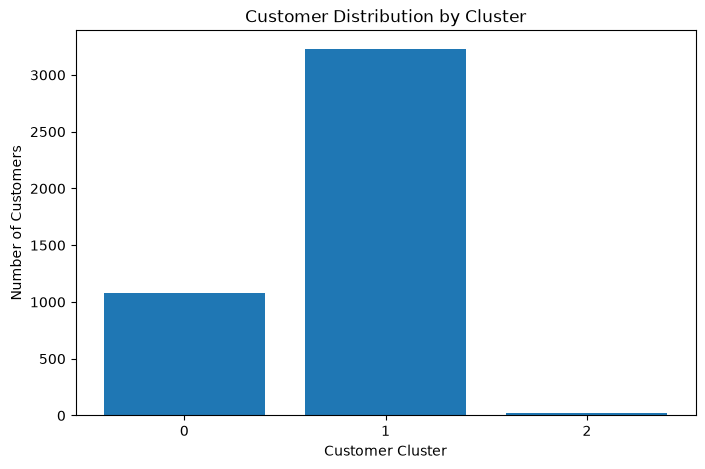

In [21]:
import matplotlib.pyplot as plt

cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution by Cluster")
plt.show()

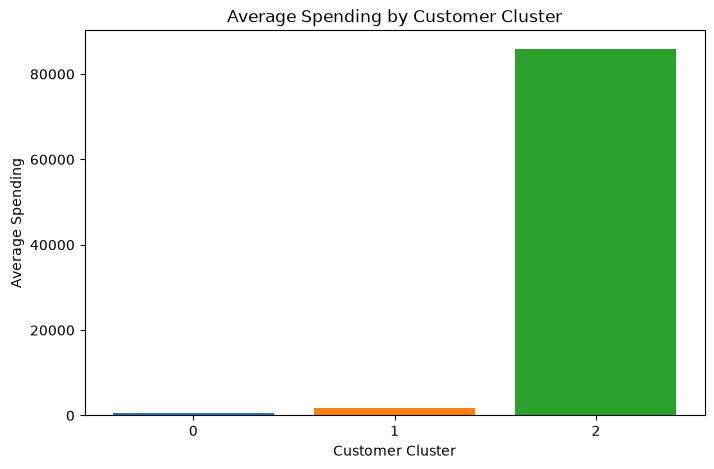

In [22]:
cluster_summary = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()

plt.figure(figsize=(8, 5))

for cluster in cluster_summary.index:
    plt.bar(
        str(cluster),
        cluster_summary.loc[cluster, "Monetary"]
    )

plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending")
plt.title("Average Spending by Customer Cluster")
plt.show()

In [23]:
import matplotlib.pyplot as plt

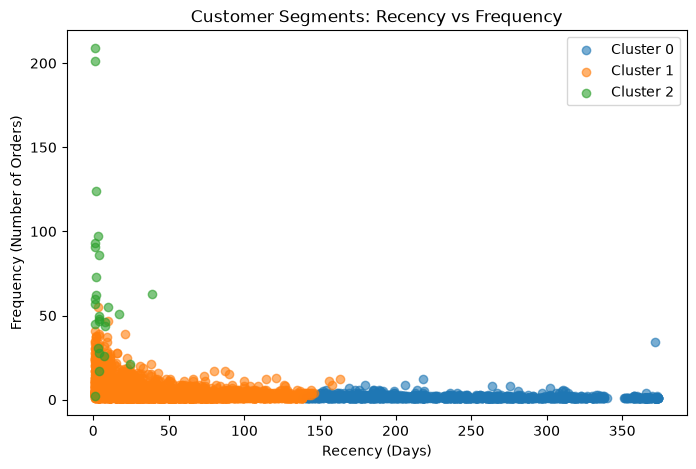

In [24]:
plt.figure(figsize=(8, 5))

for cluster in sorted(rfm["Cluster"].unique()):
    cluster_data = rfm[rfm["Cluster"] == cluster]
    plt.scatter(
        cluster_data["Recency"],
        cluster_data["Frequency"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.xlabel("Recency (Days)")
plt.ylabel("Frequency (Number of Orders)")
plt.title("Customer Segments: Recency vs Frequency")
plt.legend()
plt.show()

In [25]:
print(cluster_summary)

            Recency  Frequency      Monetary
Cluster                                     
0        247.106285   1.582255    631.424206
1         41.454180   4.672755   1855.942345
2          6.038462  66.423077  85904.351538


In [26]:
final_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

print(final_summary)

         Customer_Count  Average_Recency  Average_Frequency  Average_Monetary
Cluster                                                                      
0                  1082           247.11               1.58            631.42
1                  3230            41.45               4.67           1855.94
2                    26             6.04              66.42          85904.35


## Customer Segmentation Insights

The K-Means clustering algorithm divided customers into three groups based on Recency, Frequency, and Monetary value.

### Cluster 0: Inactive Customers

These customers have an average recency of approximately 247 days, a frequency of 1.58 orders, and average spending of 631.42.

**Recommendation:** Send re-engagement emails, personalized discounts, and special return offers to encourage repeat purchases.

### Cluster 1: Regular Customers

These customers have an average recency of approximately 41 days, a frequency of 4.67 orders, and average spending of 1,855.94.

**Recommendation:** Encourage repeat purchases through product recommendations, seasonal promotions, and loyalty rewards.

### Cluster 2: High-Value Customers

These customers have an average recency of approximately 6 days, a frequency of 66.42 orders, and average spending of 85,904.35.

**Recommendation:** Provide VIP benefits, exclusive offers, and personalized loyalty rewards to maintain customer relationships.

### Conclusion

Customer segmentation helps businesses understand different purchasing behaviours. These insights can support targeted marketing campaigns, improve customer retention, and help businesses build stronger customer relationships.
